In [1]:
#IMports needed for assignment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Initialisation for the assignment such as the seed and data
Seed = 117
data_path = "/home/stefan_stringer/FinalSemester/Deep Learning/Advanced stat/Assignment/Second one/MexicoCovid19Data.csv"
PREDICTORS = ["SEX", "PATIENT_TYPE", "AGE", "ASTHMA", "TOBACCO"]

dataframe = pd.read_csv(data_path, index_col = 0)
dataframe

,SEX,PATIENT_TYPE,AGE,ASTHMA,TOBACCO,HAS_DIED
1,1,1,76,1,0,0
2,0,0,78,0,0,0
3,0,1,30,0,0,0
4,1,1,30,0,0,0
5,0,1,32,0,0,0
...,...,...,...,...,...,...
996,0,1,28,0,0,0
997,1,1,14,0,0,0
998,1,1,62,0,0,0
999,1,1,33,0,0,0


# A) Plot and summarise the data

## I want to summarise the data in a few points, so the first being the age of the patients, next will be mortality rates by the type of patient they are (Home or hospital), and finally

Text(0, 0.5, 'Mortality Rate')

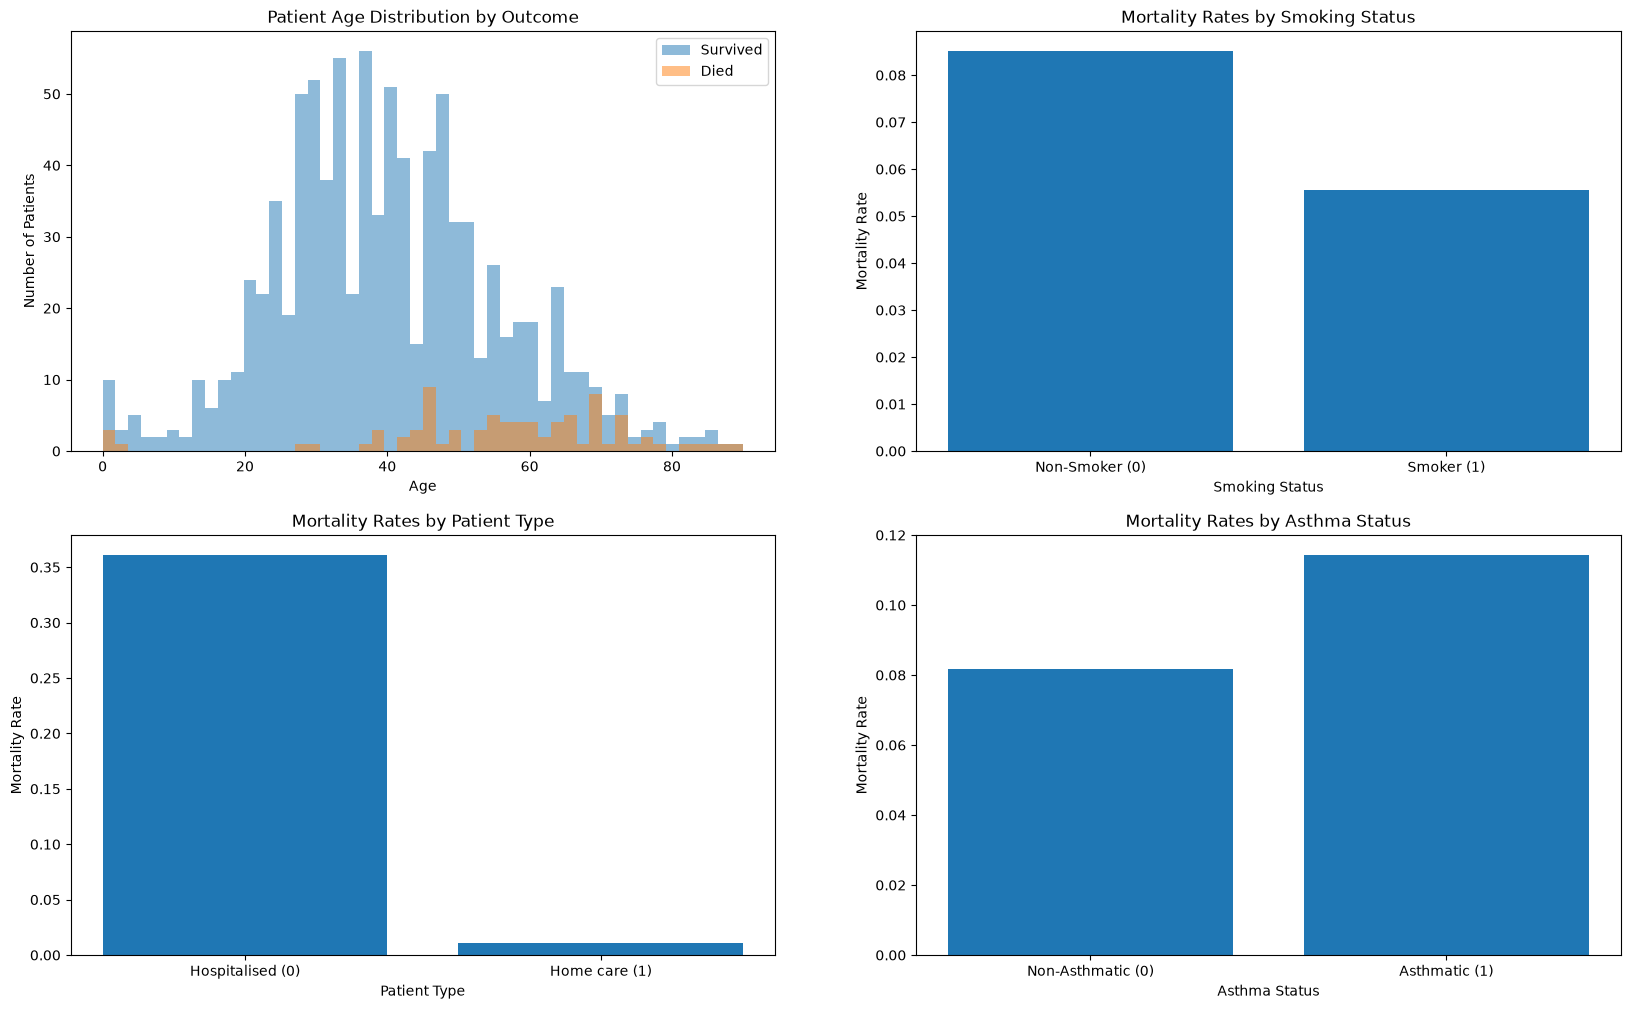

In [3]:
fig, axes = plt.subplots(2,2, figsize=(20, 12))

#First is patient age range:
for died, label in [(0, "Survived"), (1, "Died")]:
    axes[0,0].hist(dataframe[dataframe["HAS_DIED"] == died]["AGE"], bins=50, alpha=0.5, label=label)

axes[0,0].set_title("Patient Age Distribution by Outcome")
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("Number of Patients")
axes[0,0].legend()

#Second is mortality rates by patient type:
mortality_rates = dataframe.groupby("PATIENT_TYPE")["HAS_DIED"].mean()
axes[1,0].bar(["Hospitalised (0)", "Home care (1)"], mortality_rates.values)
axes[1,0].set_title("Mortality Rates by Patient Type")
axes[1,0].set_xlabel("Patient Type")
axes[1,0].set_ylabel("Mortality Rate")

#Third is mortality rates by patient being a smoker vs non smoker:
mortality_rates_smoker = dataframe.groupby("TOBACCO")["HAS_DIED"].mean()
axes[0,1].bar(["Non-Smoker (0)", "Smoker (1)"], mortality_rates_smoker.values)
axes[0,1].set_title("Mortality Rates by Smoking Status")
axes[0,1].set_xlabel("Smoking Status")
axes[0,1].set_ylabel("Mortality Rate")

#Fourth is mortality rates by patient being asthematic vs non asthmatic:
mortality_rates_asthma = dataframe.groupby("ASTHMA")["HAS_DIED"].mean()
axes[1,1].bar(["Non-Asthmatic (0)", "Asthmatic (1)"], mortality_rates_asthma.values)
axes[1,1].set_title("Mortality Rates by Asthma Status")
axes[1,1].set_xlabel("Asthma Status")
axes[1,1].set_ylabel("Mortality Rate")


# (b) Apply the casl_glm_nr_logistic() function from CASL page 127 to estimate the parameters in
# a standard logistic regression model for the data. Interpret the estimated coefficients of the model.
# Make sure (and argue why) your interpretation and the selected plots in (a) are in accordance.


In [4]:
def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

#function found in book with code for R, page 127, with translation to make into python as I prefer python to R
# casl_glm_nr_logistic <-
#   function(X, y, maxit = 25L, tol = 1e-10)
#   {
#     beta <- rep(0, ncol(X))                           same as: beta = np.zeros(X.shape[1])
#     for (j in seq(1L, maxit))
#     {
#       b_old <- beta
#       p <- 1 / (1 + exp(- X %*% beta))               same as: prob = sigmoid(X @ beta)
#       W <- as.numeric(p * (1 - p))                 same as: w = prob * (1 - prob)
#       XX <- crossprod(X, diag(W) %*% X)            same as info = X.T @ (X * w[:, None]) #Had to use assitance on this line
#       score <- t(X) %*% (y - p)                    same as: score = X.T @ (y - prob)
#       delta <- solve(XX, score)                     is just np.linalg.solve(info, score)
#       beta <- beta + delta                          left as exercise for reader as easy
#       if (sqrt(crossprod(beta - b_old)) < tol) break      its an if statement under tolerance for sqrt(sum((beta - beta_old) ** 2))
#     }
#     beta
#   }
def nr_logistic(X, y, lam=0.0, max_iter=25, tolerance=1e-10):
    beta = np.zeros(X.shape[1])
    pen = np.ones(X.shape[1])
    pen[0] = 0.0
    P = np.diag(pen)

    for _ in range(max_iter):
        beta_old = beta.copy()
        prob = sigmoid(X @ beta)
        w = prob * (1 - prob)
        score = X.T @ (y - prob) - lam * (P @ beta) #adding the lambda here incoporates the ridge regression penalty into the score calculation
        info = X.T @ (X * w[:, None]) + lam * P #same here. Otherwise if 0, this element does nothing! easy implementation
        delta = np.linalg.solve(info, score)
        beta = beta + delta

        if np.sqrt(((beta - beta_old) ** 2).sum()) < tolerance:
            break
    return beta

#I got help with how to do this, as this was something that really held me up for a bit.
# However making it a dataframe was much easier, as I am used to working with pandas in python
def make_design_matrix(df):
    intercept     = np.ones(len(df))
    sex           = df.SEX.to_numpy(float)
    patient_type  = df.PATIENT_TYPE.to_numpy(float)
    age           = df.AGE.to_numpy(float)
    asthma        = df.ASTHMA.to_numpy(float)
    tobacco       = df.TOBACCO.to_numpy(float)
    y             = df.HAS_DIED.to_numpy(float)

    X = np.column_stack([intercept, sex, patient_type, age, asthma, tobacco])
    names = ["intercept", "SEX", "PATIENT_TYPE", "AGE", "ASTHMA", "TOBACCO"]
    return X, y, names


X, y, names = make_design_matrix(dataframe)
beta_std = nr_logistic(X, y)
beta_std

array([-1.9190826 , -0.71255164, -3.57751436,  0.03101216,  0.83113579,
       -0.48945714])

In [5]:
results = pd.DataFrame({"Coefficient": beta_std}, index=names)
results

,Coefficient
intercept,-1.919083
SEX,-0.712552
PATIENT_TYPE,-3.577514
AGE,0.031012
ASTHMA,0.831136
TOBACCO,-0.489457


In [6]:
# The odds ratio is the exponent of the coefficient. This comes from the fact that the logistic regression model is log-odds,
# so taking exponent on each side the coefficients gives us the odds ratios.
results["Odds Ratio"] = np.exp(results["Coefficient"])
results

,Coefficient,Odds Ratio
intercept,-1.919083,0.146742
SEX,-0.712552,0.490391
PATIENT_TYPE,-3.577514,0.027945
AGE,0.031012,1.031498
ASTHMA,0.831136,2.295925
TOBACCO,-0.489457,0.612959


## Write up for logistic regression models coefficients, and the plots shown:

The four plots I did previously started from the most intuitive thing to look at, the survival/death distribution of the data based by age. Showing that there is an unfortunate number of very young, and an unsurprising number of middle age to older people, with 20s and 30s mostly uneffected.

From this the natural progression in my head, was looking at the mortality rates for patient type, and both smoking and asthma, considering that peoples respitory issues could contribute.

So I clearly did this in python, and got the above coefficients.

The obvious one being patient type, which seems rather obvious. If you are admitted to hospital, it must be serious, so a funny one to make a conclusion from.

Next, Asthmatics had a higher rate of mortality than non-asthmatics, This was also expected.

Smoking was surprisingly low on the mortality scale. I dont really know why this the case?

Also age, as in the plot, was significant the older you get. Its fair to say that there is an increase for each year, as the older you are, the higher chance of death (also visually seen)

My intercept, (Come back to this later)

## 

## (c) Derive the Newton-Raphson algorithm for logistic regression with a ridge penalty, and modify the
## CASL implementation of standard logistic regression to logistic regression with a ridge penalty

In [9]:
#Main difference between ridge and standard is that our lambda value must be higher than zero
#This is added as an input, and the function was made such that adding this will work as needed
beta_ridge = nr_logistic(X, y, lam=10.0)
beta_ridge

array([-3.06123142, -0.38581864, -1.8591949 ,  0.04103236,  0.13067022,
       -0.10353963])

In [10]:
results_ridge = pd.DataFrame({"Coefficient": beta_ridge}, index=names)
results_ridge["Odds Ratio"] = np.exp(results_ridge["Coefficient"])
results_ridge

,Coefficient,Odds Ratio
intercept,-3.061231,0.046830
SEX,-0.385819,0.679894
PATIENT_TYPE,-1.859195,0.155798
AGE,0.041032,1.041886
ASTHMA,0.130670,1.139592
TOBACCO,-0.103540,0.901640


In [11]:
results_ridge["coefficient difference"] = results_ridge["Coefficient"] - results["Coefficient"]
results_ridge

,Coefficient,Odds Ratio,coefficient difference
intercept,-3.061231,0.046830,-1.142149
SEX,-0.385819,0.679894,0.326733
PATIENT_TYPE,-1.859195,0.155798,1.718319
AGE,0.041032,1.041886,0.010020
ASTHMA,0.130670,1.139592,-0.700466
TOBACCO,-0.103540,0.901640,0.385918


It seems as though here everything but age went down in terms of how much it contributed to deaths.
Age is clearly important, and a high contributer. However being asthematic and smoking were things that shrinked a lot? This really surpises me.
The intercept moved a lot too, maybe because it was penalised before so here it can move where ever to keep the death rate? This was a surprising result, that it couldnt reduce some covariants to zero, and gave this.

## (d) Use your implementation to analyze the data using logistic regression with a ridge penalty. The
## tuning parameter for the ridge penalty should be estimated using k-fold cross-validation where
## k > 1. Compare the ridge coefficients to the coefficients from the standard model.


In [ ]:
# https://www.geeksforgeeks.org/machine-learning/stratified-k-fold-cross-validation/
# and https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss

k = 10
lambdas = np.logspace(-4, 4, 10) #for now we pick 10 differet values
folds = list(StratifiedKFold(n_splits=k, shuffle=True, random_state=Seed).split(X, y))

cvloss = []

for l in lambdas:
    foldLoss = []
    for train_idx, value_idx in folds:
        
        beta_fold = nr_logistics
